<h1 align="center" style="color:#1f77b4;">
    Hand Written Digits Classification
</h1>


<h7 align="center" style="color:#1f7;">
    Data Loading, Preperation and Exploration
</h7>


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim 
from torchvision import datasets
from torchvision.transforms import ToTensor,Normalize,Compose
from torch.utils.data import DataLoader

In [46]:
if torch.cuda.is_available():
    device=torch.device("cuda")
else:
    device=torch.device("cpu")

print(f"Device is '{device}'")

Device is 'cuda'


In [47]:
transforms= Compose(
    [
        ToTensor(),
        Normalize(0.5,0.5)
    ]
)

train_data=datasets.MNIST(
    root="Data",
    download=True,
    transform=transforms,
    train=True
)

test_data=datasets.MNIST(
    root="Data",
    download=True,
    transform=transforms,
    train=False
)

In [48]:
len(train_data)

60000

In [49]:
len(test_data)

10000

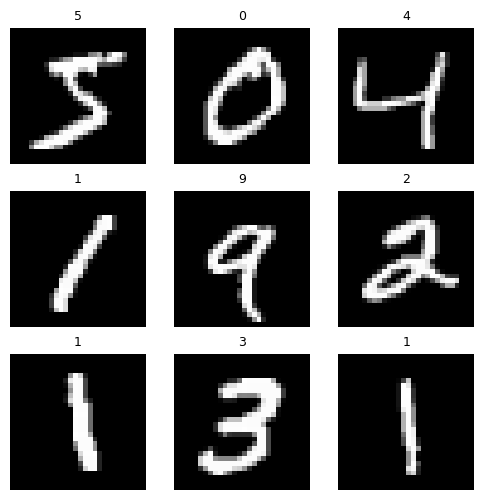

In [50]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    image, label =train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(label, fontsize=9)
    ax.axis("off")

plt.show()

In [51]:
train_data_loader=DataLoader(train_data,batch_size=64,shuffle=True)
test_data_loader=DataLoader(test_data,batch_size=64,shuffle=True)
data_iter=iter(train_data)
images,labels=next(data_iter)

<h7 align="center" style="color:#1f7;">
    Neural Network Training and Evaluation
</h7>


In [53]:
from turtle import forward


class DigitsClassification(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28,128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,10),
            nn.Softmax()
        )
    def forward(self,x):
        return self.network(x)

In [54]:
model=DigitsClassification()
optimizer=optim.Adam(model.parameters(),lr=0.001)
loss_func=nn.CrossEntropyLoss()

In [57]:
epochs=6
for epoch in range(epochs):
    running_loss=0
    for images, labels in train_data_loader:
        # 1. Forward Pass
        pred=model(images)
        loss=loss_func(pred,labels)
        # 2. Backward Pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss+=loss
    print(f"Epoch : {epoch},  Loss : {running_loss/len(train_data_loader)}")


C:\Users\Trijesh Kondapuram\AppData\Roaming\Python\Python314\site-packages\torch\nn\modules\module.py:1775: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


Epoch : 0,  Loss : 1.5023176670074463
Epoch : 1,  Loss : 1.500478744506836
Epoch : 2,  Loss : 1.4975497722625732
Epoch : 3,  Loss : 1.4959685802459717
Epoch : 4,  Loss : 1.4953514337539673
Epoch : 5,  Loss : 1.4933319091796875


In [66]:
from torch import no_grad
import numpy

model.eval()
all_predicted=[]
all_labels=[]
with no_grad():
    for images,labels in test_data_loader:
        outputs=model(images)
        _,predicted=torch.max(outputs.data,1)

        all_predicted.extend(predicted.numpy())
        all_labels.extend(labels.numpy())



C:\Users\Trijesh Kondapuram\AppData\Roaming\Python\Python314\site-packages\torch\nn\modules\module.py:1775: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


In [68]:
report=classification_report(all_labels,all_predicted)
print(report)

              precision    recall  f1-score   support

           0       0.96      0.99      0.97       980
           1       0.99      0.97      0.98      1135
           2       0.96      0.97      0.96      1032
           3       0.98      0.97      0.97      1010
           4       0.97      0.97      0.97       982
           5       0.97      0.97      0.97       892
           6       0.98      0.97      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.94      0.97      0.96       974
           9       0.97      0.95      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [69]:
cm=confusion_matrix(all_labels,all_predicted)
print(cm)

[[ 971    0    0    0    0    4    1    2    2    0]
 [   0 1105   11    2    0    1    1    1   14    0]
 [   7    0 1000    1    5    0    2   10    6    1]
 [   1    0    4  975    0    8    0    7   11    4]
 [   2    0    4    0  955    1    4    2    4   10]
 [   9    0    0    4    0  863    6    2    6    2]
 [  10    2    3    1    3    5  928    1    5    0]
 [   1    4   16    7    3    0    0  988    3    6]
 [   8    0    3    2    3    4    2    5  944    3]
 [   5    3    1    5   16    4    1   11    5  958]]


<Axes: >

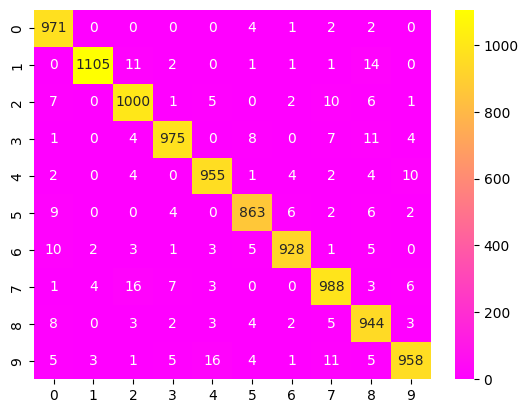

In [73]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='spring'
)
